In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["figure.dpi"] = 100
plt.show()

In [4]:
prices_df = pd.read_csv("prices_round_1_day_-1.csv")
trades_df = pd.read_csv("trades_round_1_day_-1.csv")

print(prices_df)

       day  timestamp               product  bid_price_1  bid_volume_1  \
0       -1          0  INTARIAN_PEPPER_ROOT      10991.0          15.0   
1       -1          0     ASH_COATED_OSMIUM          NaN           NaN   
2       -1        100     ASH_COATED_OSMIUM       9984.0          11.0   
3       -1        100  INTARIAN_PEPPER_ROOT      10994.0           9.0   
4       -1        200     ASH_COATED_OSMIUM       9985.0          15.0   
...    ...        ...                   ...          ...           ...   
19995   -1     999700  INTARIAN_PEPPER_ROOT      11993.0          10.0   
19996   -1     999800  INTARIAN_PEPPER_ROOT      11993.0          12.0   
19997   -1     999800     ASH_COATED_OSMIUM       9994.0          13.0   
19998   -1     999900     ASH_COATED_OSMIUM       9994.0          10.0   
19999   -1     999900  INTARIAN_PEPPER_ROOT      11990.0          25.0   

       bid_price_2  bid_volume_2  bid_price_3  bid_volume_3  ask_price_1  \
0              NaN           NaN   

In [5]:
print(f"Prices shape: {prices_df.shape}  ({prices_df.shape[0]} rows x {prices_df.shape[1]} columns)")
print(f"Trades shape: {trades_df.shape}  ({trades_df.shape[0]} rows x {trades_df.shape[1]} columns)")
print(f"\nProducts in prices: {prices_df['product'].unique()}")
print(f"Products in trades: {trades_df['symbol'].unique()}")
print(f"\nTimestamp range: {prices_df['timestamp'].min()} to {prices_df['timestamp'].max()}")
print(f"Number of unique timestamps: {prices_df['timestamp'].nunique()}")
print(f"Timestamp step size: {sorted(prices_df['timestamp'].unique())[1] - sorted(prices_df['timestamp'].unique())[0]}")
print(f"\n=> {prices_df['timestamp'].nunique()} iterations, each 100ms apart = 10,000 iterations per day")

Prices shape: (20000, 17)  (20000 rows x 17 columns)
Trades shape: (760, 7)  (760 rows x 7 columns)

Products in prices: <ArrowStringArray>
['INTARIAN_PEPPER_ROOT', 'ASH_COATED_OSMIUM']
Length: 2, dtype: str
Products in trades: <ArrowStringArray>
['ASH_COATED_OSMIUM', 'INTARIAN_PEPPER_ROOT']
Length: 2, dtype: str

Timestamp range: 0 to 999900
Number of unique timestamps: 10000
Timestamp step size: 100

=> 10000 iterations, each 100ms apart = 10,000 iterations per day


In [6]:
print("=== Prices CSV: Summary Statistics ===")
prices_df.describe()

=== Prices CSV: Summary Statistics ===


,day,timestamp,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss
count,20000.0,20000.0000,19187.000000,19187.000000,12999.000000,12999.000000,382.000000,382.000000,19223.000000,19223.000000,13060.000000,13060.000000,412.000000,412.000000,20000.000000,20000.0
mean,-1.0,499950.0000,10742.745244,12.851723,10740.474729,22.073159,10560.133508,22.913613,10758.531603,12.841908,10761.277182,22.062098,10604.237864,22.764563,10732.156275,0.0
std,0.0,288682.3503,777.813942,4.980506,777.453525,4.493429,760.635692,3.903747,776.454320,4.965119,777.229203,4.492471,738.001300,4.102151,893.711228,0.0
min,-1.0,0.0000,9980.000000,2.000000,9980.000000,4.000000,9981.000000,10.000000,9989.000000,1.000000,9994.000000,2.000000,10001.000000,8.000000,0.000000,0.0
25%,-1.0,249975.0000,9993.000000,10.000000,9991.000000,19.000000,9989.000000,20.250000,10009.000000,10.000000,10011.000000,19.000000,10011.000000,20.000000,10001.000000,0.0
50%,-1.0,499950.0000,10009.000000,12.000000,10001.000000,22.000000,9993.000000,23.000000,11006.000000,12.000000,11009.000000,22.000000,10015.500000,23.000000,10015.500000,0.0
75%,-1.0,749925.0000,11494.000000,14.000000,11495.000000,25.000000,11396.250000,25.000000,11508.000000,14.000000,11510.000000,25.000000,11356.750000,26.000000,11499.500000,0.0
max,-1.0,999900.0000,11995.000000,30.000000,11990.000000,30.000000,11965.000000,30.000000,12009.000000,30.000000,12009.000000,30.000000,11993.000000,30.000000,12006.000000,0.0


In [7]:
print("=== Trades CSV: Summary Statistics ===")
print(f"Total trades: {len(trades_df)}")
print(f"\nTrades per product:")
print(trades_df["symbol"].value_counts())
print(f"\nTrade price statistics per product:")
trades_df.groupby("symbol")["price"].describe()

=== Trades CSV: Summary Statistics ===
Total trades: 760

Trades per product:
symbol
ASH_COATED_OSMIUM       425
INTARIAN_PEPPER_ROOT    335
Name: count, dtype: int64

Trade price statistics per product:


,count,mean,std,min,25%,50%,75%,max
symbol,,,,,,,,
ASH_COATED_OSMIUM,425.0,10000.774118,9.102705,9982.0,9993.0,10001.0,10009.0,10019.0
INTARIAN_PEPPER_ROOT,335.0,11503.086567,285.803084,10995.0,11263.5,11511.0,11749.5,12005.0


,timestamp,buyer,seller,symbol,currency,price,quantity
0,2800,NaN,NaN,ASH_COATED_OSMIUM,XIRECS,9985.0,10
1,3000,NaN,NaN,INTARIAN_PEPPER_ROOT,XIRECS,10999.0,8
2,4200,NaN,NaN,INTARIAN_PEPPER_ROOT,XIRECS,10995.0,4
3,5200,NaN,NaN,ASH_COATED_OSMIUM,XIRECS,10004.0,6
4,5200,NaN,NaN,ASH_COATED_OSMIUM,XIRECS,9986.0,9
...,...,...,...,...,...,...,...
755,995200,NaN,NaN,INTARIAN_PEPPER_ROOT,XIRECS,11989.0,4
756,995800,NaN,NaN,ASH_COATED_OSMIUM,XIRECS,9993.0,6
757,997100,NaN,NaN,ASH_COATED_OSMIUM,XIRECS,10009.0,6
758,997800,NaN,NaN,ASH_COATED_OSMIUM,XIRECS,9994.0,5


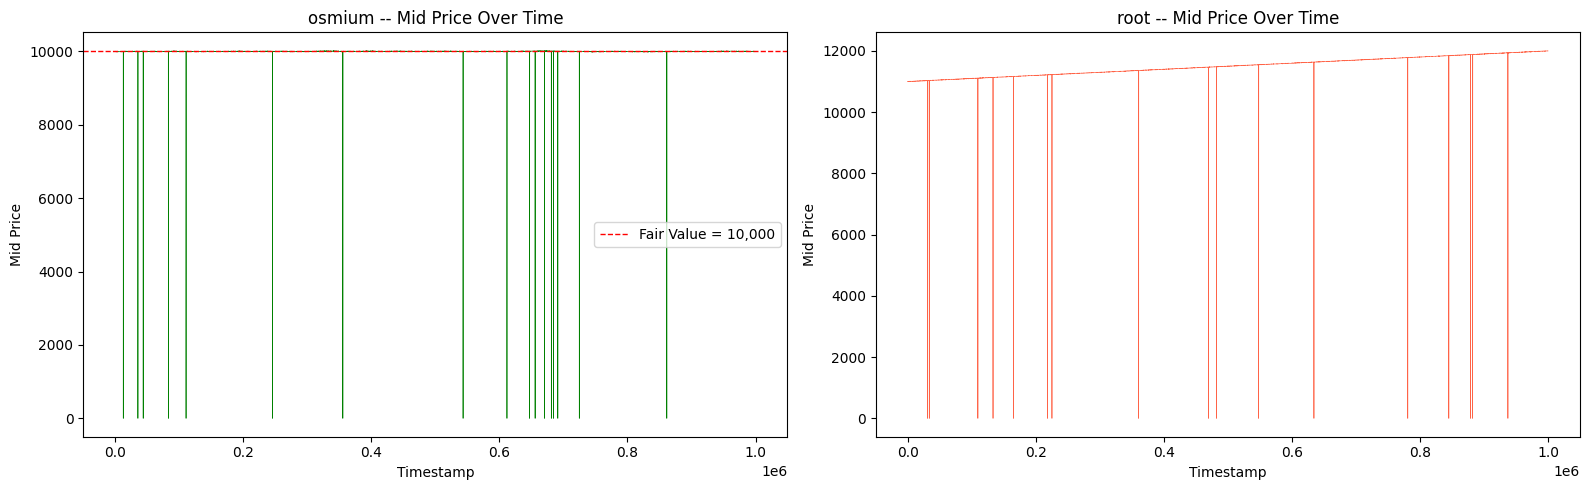

osmium mid_price -- mean: 9983.83, std: 412.04, min: 0.0, max: 10019.0
root mid_price -- mean: 11480.48, std: 554.67, min: 0.0, max: 12006.0


In [11]:
osmium = prices_df[prices_df["product"] == "ASH_COATED_OSMIUM"].copy()
root = prices_df[prices_df["product"] == "INTARIAN_PEPPER_ROOT"].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(osmium["timestamp"], osmium["mid_price"], linewidth=0.5, color="green")
axes[0].set_title("osmium -- Mid Price Over Time")
axes[0].set_xlabel("Timestamp")
axes[0].set_ylabel("Mid Price")
axes[0].axhline(y=10000, color="red", linestyle="--", linewidth=1, label="Fair Value = 10,000")
axes[0].legend()

axes[1].plot(root["timestamp"], root["mid_price"], linewidth=0.5, color="tomato")
axes[1].set_title("root -- Mid Price Over Time")
axes[1].set_xlabel("Timestamp")
axes[1].set_ylabel("Mid Price")

plt.tight_layout()
plt.show()

print(f"osmium mid_price -- mean: {osmium['mid_price'].mean():.2f}, "
      f"std: {osmium['mid_price'].std():.2f}, "
      f"min: {osmium['mid_price'].min()}, max: {osmium['mid_price'].max()}")
print(f"root mid_price -- mean: {root['mid_price'].mean():.2f}, "
      f"std: {root['mid_price'].std():.2f}, "
      f"min: {root['mid_price'].min()}, max: {root['mid_price'].max()}")

In [17]:
osmium[osmium['mid_price']<9000]

,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss
254,-1,12700,ASH_COATED_OSMIUM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
711,-1,35500,ASH_COATED_OSMIUM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
877,-1,43800,ASH_COATED_OSMIUM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
1663,-1,83100,ASH_COATED_OSMIUM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
2214,-1,110700,ASH_COATED_OSMIUM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
4914,-1,245700,ASH_COATED_OSMIUM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
7111,-1,355500,ASH_COATED_OSMIUM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
10867,-1,543300,ASH_COATED_OSMIUM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
12237,-1,611800,ASH_COATED_OSMIUM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
12943,-1,647100,ASH_COATED_OSMIUM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0


In [18]:
prices_df_lst = [prices_df]

In [19]:
prices_df2 = pd.read_csv('prices_round_1_day_-2.csv')

In [28]:
prices_df_lst = [prices_df2,prices_df]
prices_df_3 = pd.read_csv('prices_round_1_day_0.csv')
prices_df_3
prices_df_lst.append(prices_df_3)

In [20]:
osmium = prices_df2[prices_df2['product']=='ASH_COATED_OSMIUM']

In [24]:
osmium = osmium[osmium['mid_price']!=0]

<Axes: >

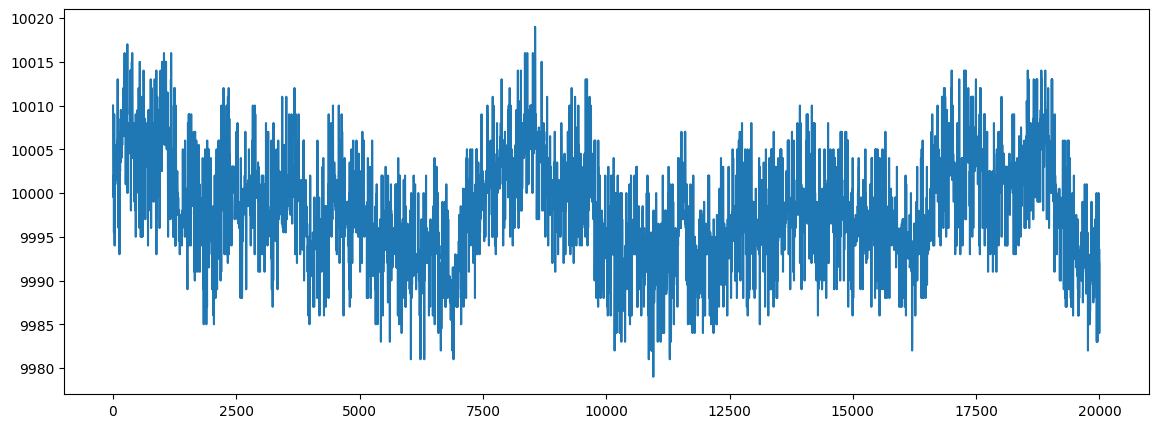

In [25]:
osmium['mid_price'].plot()

In [29]:
comp_prices_df = pd.concat(prices_df_lst)
os_df = comp_prices_df[comp_prices_df['product']=='ASH_COATED_OSMIUM']
root_df = comp_prices_df[comp_prices_df['product']=='INTARIAN_PEPPER_ROOT']

In [ ]:
os_df = os_df[os_df['mid_price']!=0]
root_df = root_df[root_df['mid_price']!=0]

In [34]:
os_df.reset_index(inplace=True)
root_df.reset_index(inplace=True)

<Axes: >

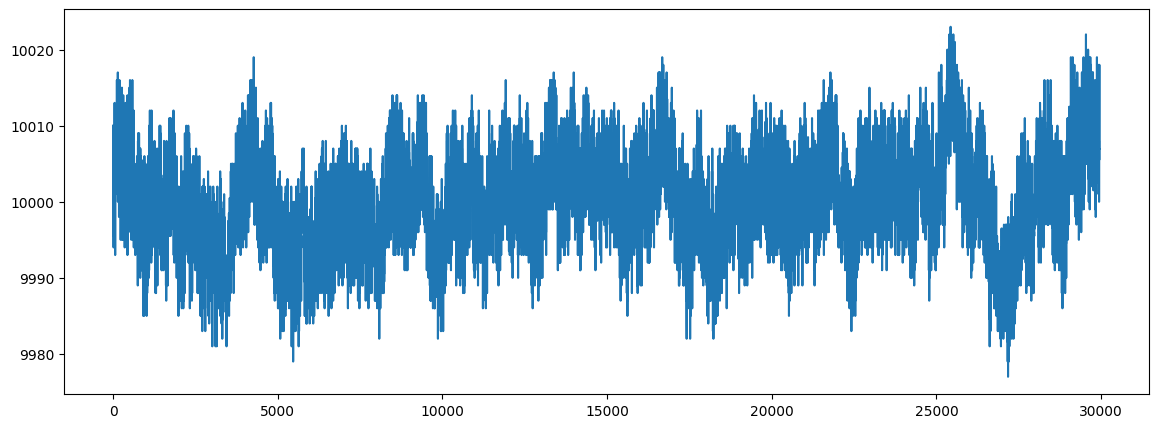

In [35]:
os_df['mid_price'].plot()

<Axes: >

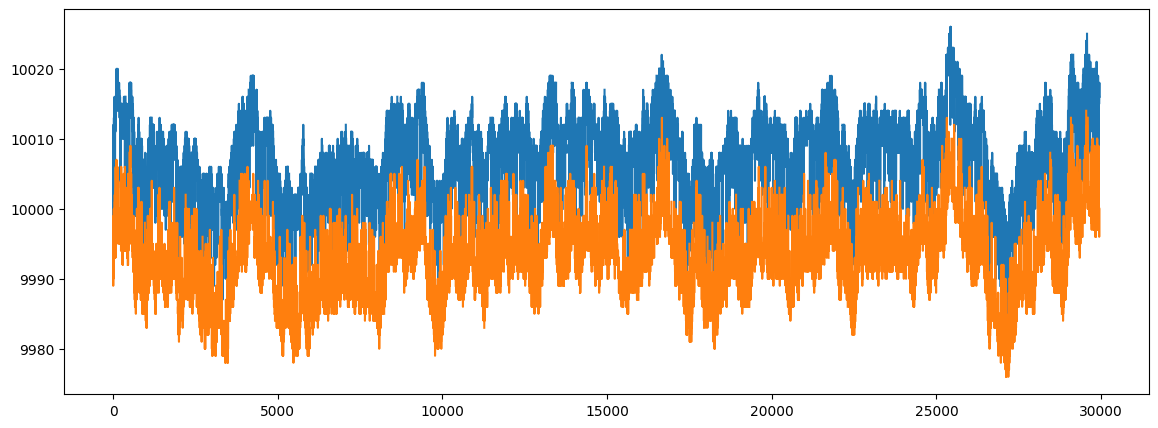

In [68]:
os_df['ask_price_1'].plot()
os_df['bid_price_1'].plot()

<Axes: >

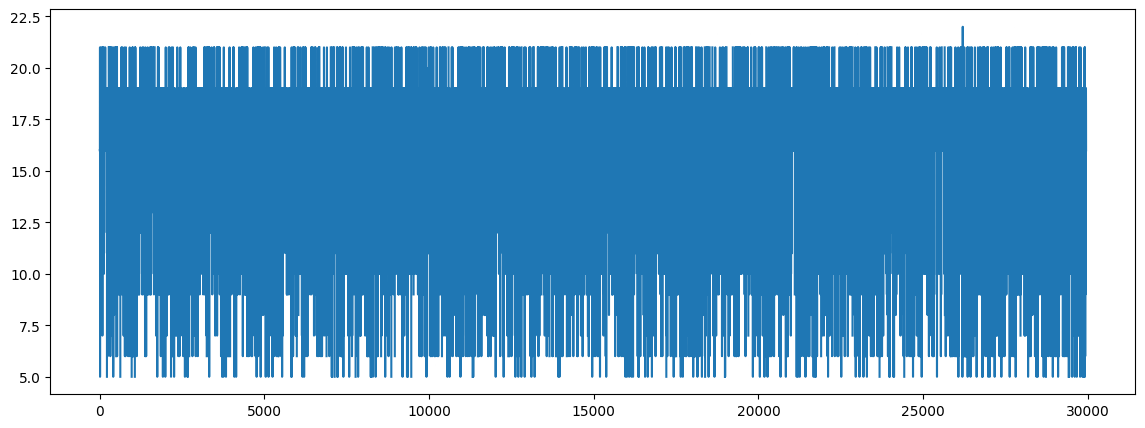

In [72]:
diff = os_df['ask_price_1'] - os_df['bid_price_1']
diff.plot()

<Axes: >

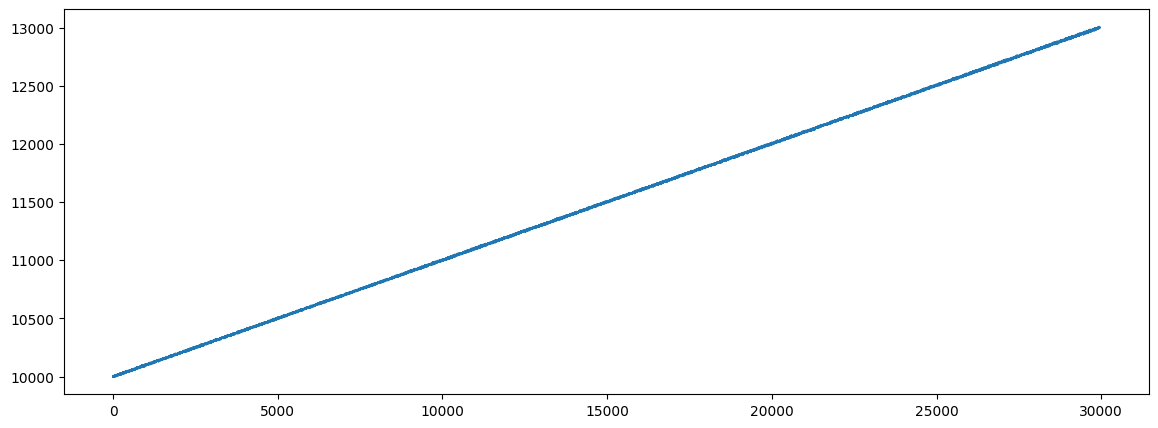

In [36]:
root_df['mid_price'].plot()

<Axes: >

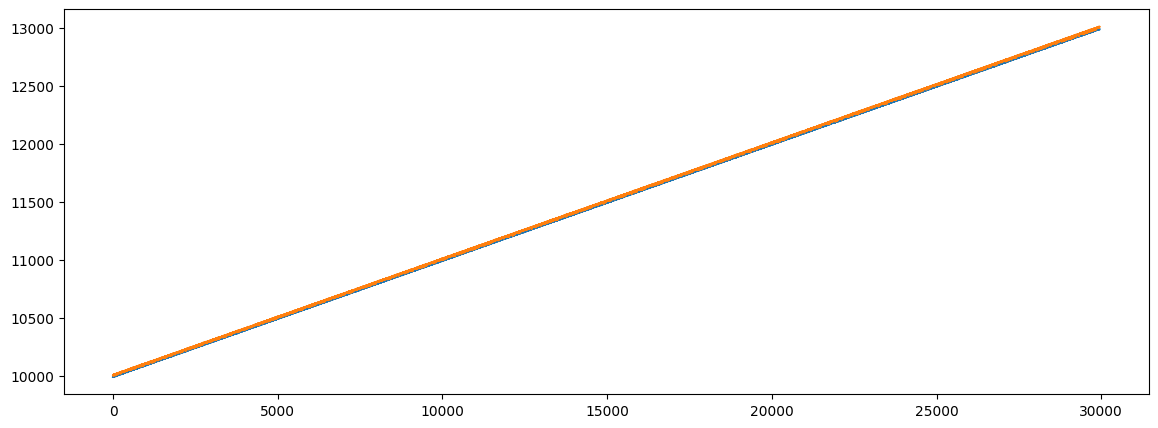

In [39]:
root_df['bid_price_1'].plot()
root_df['ask_price_1'].plot()

In [ ]:
"""
Given Statergy for execution:
1. For the root product as it can be seen it shows a linear trend for strictly increasing so best thing will to buy and hold as soon as possible take whatever ask in maximum volume.
2. For Osmium it follows a mean reversion statergy like that for tomatoes 
"""

## Backtest: Trader vs Sample CSV Data

In [47]:
import sys, importlib, math
from collections import defaultdict

sys.path.insert(0, ".")
import datamodel
importlib.reload(datamodel)
from datamodel import OrderDepth, TradingState, Order, Listing, Observation

import trader as trader_module
importlib.reload(trader_module)
from trader import Trader

# ── Load all 3 day files ──
csv_files = [
    "prices_round_1_day_-2.csv",
    "prices_round_1_day_-1.csv",
    "prices_round_1_day_0.csv",
]

all_prices = []
for f in csv_files:
    try:
        df = pd.read_csv(f)
        all_prices.append(df)
        print(f"Loaded {f}: {len(df)} rows")
    except FileNotFoundError:
        print(f"Skipping {f} (not found)")

prices_all = pd.concat(all_prices, ignore_index=True)
print(f"\nTotal rows: {len(prices_all)}")
print(f"Days: {sorted(prices_all['day'].unique())}")
print(f"Products: {list(prices_all['product'].unique())}")

Loaded prices_round_1_day_-2.csv: 20000 rows
Loaded prices_round_1_day_-1.csv: 20000 rows
Loaded prices_round_1_day_0.csv: 20000 rows

Total rows: 60000
Days: [np.int64(-2), np.int64(-1), np.int64(0)]
Products: ['INTARIAN_PEPPER_ROOT', 'ASH_COATED_OSMIUM']


In [48]:
def build_order_depth(row):
    """Build an OrderDepth from a prices CSV row."""
    od = OrderDepth()
    for level in range(1, 4):
        bp = row.get(f"bid_price_{level}")
        bv = row.get(f"bid_volume_{level}")
        if pd.notna(bp) and pd.notna(bv):
            od.buy_orders[int(bp)] = int(bv)
        ap = row.get(f"ask_price_{level}")
        av = row.get(f"ask_volume_{level}")
        if pd.notna(ap) and pd.notna(av):
            od.sell_orders[int(ap)] = -int(av)  # sell volumes are negative in IMC
    return od


def simulate_fills(orders, order_depth):
    """
    Simulate order fills against the order book (taking only).
    Passive/making orders won't fill here -- they need real counterparties.
    Returns list of (price, qty) tuples. Positive qty = buy, negative = sell.
    """
    fills = []
    sell_levels = dict(sorted(order_depth.sell_orders.items()))
    buy_levels = dict(sorted(order_depth.buy_orders.items(), reverse=True))

    for order in orders:
        if order.quantity > 0:
            remaining = order.quantity
            for ask_price in sorted(sell_levels.keys()):
                if ask_price > order.price or remaining <= 0:
                    break
                available = abs(sell_levels[ask_price])
                filled = min(remaining, available)
                if filled > 0:
                    fills.append((ask_price, filled))
                    remaining -= filled
                    sell_levels[ask_price] += filled
                    if sell_levels[ask_price] >= 0:
                        del sell_levels[ask_price]
        elif order.quantity < 0:
            remaining = abs(order.quantity)
            for bid_price in sorted(buy_levels.keys(), reverse=True):
                if bid_price < order.price or remaining <= 0:
                    break
                available = abs(buy_levels[bid_price])
                filled = min(remaining, available)
                if filled > 0:
                    fills.append((bid_price, -filled))
                    remaining -= filled
                    buy_levels[bid_price] -= filled
                    if buy_levels[bid_price] <= 0:
                        del buy_levels[bid_price]
    return fills


def run_backtest(prices_df):
    """Run the trader against historical price data and compute PnL.
    NOTE: This only simulates 'taking' fills (crossing the spread).
    Passive limit orders (making) will only fill in the real IMC environment.
    Osmium PnL here is a lower bound.
    """
    products = ["INTARIAN_PEPPER_ROOT", "ASH_COATED_OSMIUM"]
    all_days = sorted(prices_df["day"].unique())
    history = []

    for day in all_days:
        # Reset per day (each day is independent in IMC)
        positions = defaultdict(int)
        cash = defaultdict(float)
        trader_data = ""
        trader = Trader()

        day_df = prices_df[prices_df["day"] == day]
        timestamps = sorted(day_df["timestamp"].unique())

        for ts in timestamps:
            ts_rows = day_df[day_df["timestamp"] == ts]

            order_depths = {}
            mid_prices = {}
            for _, row in ts_rows.iterrows():
                product = row["product"]
                od = build_order_depth(row)
                if od.buy_orders or od.sell_orders:
                    order_depths[product] = od
                mid_prices[product] = row["mid_price"]

            listings = {p: Listing(p, p, "XIRECS") for p in products}
            position_dict = {p: positions[p] for p in products if positions[p] != 0}
            obs = Observation({}, {})

            state = TradingState(
                traderData=trader_data,
                timestamp=ts,
                listings=listings,
                order_depths=order_depths,
                own_trades={},
                market_trades={},
                position=position_dict,
                observations=obs,
            )

            result, conversions, trader_data = trader.run(state)

            for product, orders in result.items():
                if product not in order_depths:
                    continue
                fills = simulate_fills(orders, order_depths[product])
                for price, qty in fills:
                    positions[product] += qty
                    cash[product] -= price * qty

            for product in products:
                mid = mid_prices.get(product, 0)
                if mid == 0:
                    continue
                pnl = cash[product] + positions[product] * mid
                history.append({
                    "day": day,
                    "timestamp": ts,
                    "product": product,
                    "position": positions[product],
                    "cash": cash[product],
                    "mid_price": mid,
                    "pnl": pnl,
                })

    return pd.DataFrame(history)


results_df = run_backtest(prices_all)
print("Backtest complete!")
print(f"Total rows in results: {len(results_df)}")
print("\nNOTE: Osmium PnL is a LOWER BOUND -- passive orders can't fill in CSV-only backtest.")

Backtest complete!
Total rows in results: 59897

NOTE: Osmium PnL is a LOWER BOUND -- passive orders can't fill in CSV-only backtest.


In [49]:
# ── Summary: final PnL per product per day ──
products = ["INTARIAN_PEPPER_ROOT", "ASH_COATED_OSMIUM"]

print("=" * 60)
print("BACKTEST RESULTS (taking-only fills)")
print("=" * 60)

for day in sorted(results_df["day"].unique()):
    day_data = results_df[results_df["day"] == day]
    print(f"\n--- Day {day} ---")
    day_total = 0
    for product in products:
        prod_data = day_data[day_data["product"] == product]
        if len(prod_data) > 0:
            final_pnl = prod_data.iloc[-1]["pnl"]
            final_pos = prod_data.iloc[-1]["position"]
            max_pos = prod_data["position"].abs().max()
            print(f"  {product:>25s}: PnL = {final_pnl:>12,.1f}  |  Pos = {final_pos:>4.0f}  |  Max|Pos| = {max_pos}")
            day_total += final_pnl
    print(f"  {'TOTAL':>25s}: PnL = {day_total:>12,.1f}")

grand = 0
print(f"\n{'=' * 60}")
print("PER-DAY TOTALS:")
for day in sorted(results_df["day"].unique()):
    day_data = results_df[results_df["day"] == day]
    day_total = sum(
        day_data[day_data["product"] == p].iloc[-1]["pnl"]
        for p in products if len(day_data[day_data["product"] == p]) > 0
    )
    print(f"  Day {day}: {day_total:>12,.1f}")
    grand += day_total
print(f"  Grand Total: {grand:>12,.1f}")
print("=" * 60)
print("\nNote: Osmium PnL is a LOWER BOUND. Passive limit orders only fill in the real IMC env.")

BACKTEST RESULTS (taking-only fills)

--- Day -2 ---
       INTARIAN_PEPPER_ROOT: PnL =     79,591.0  |  Pos =   80  |  Max|Pos| = 80
          ASH_COATED_OSMIUM: PnL =      2,999.0  |  Pos =   80  |  Max|Pos| = 80
                      TOTAL: PnL =     82,590.0

--- Day -1 ---
       INTARIAN_PEPPER_ROOT: PnL =     79,261.0  |  Pos =   80  |  Max|Pos| = 80
          ASH_COATED_OSMIUM: PnL =      4,945.0  |  Pos =   76  |  Max|Pos| = 80
                      TOTAL: PnL =     84,206.0

--- Day 0 ---
       INTARIAN_PEPPER_ROOT: PnL =     79,450.0  |  Pos =   80  |  Max|Pos| = 80
          ASH_COATED_OSMIUM: PnL =      5,627.0  |  Pos =  -80  |  Max|Pos| = 80
                      TOTAL: PnL =     85,077.0

PER-DAY TOTALS:
  Day -2:     82,590.0
  Day -1:     84,206.0
  Day 0:     85,077.0
  Grand Total:    251,873.0

Note: Osmium PnL is a LOWER BOUND. Passive limit orders only fill in the real IMC env.


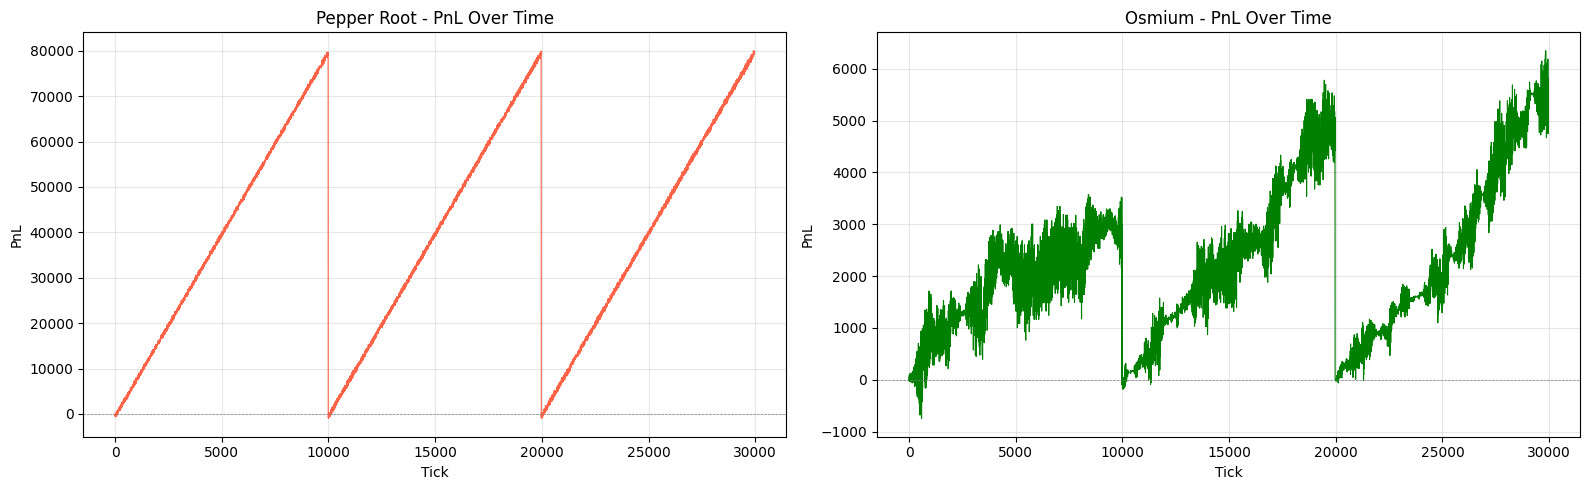

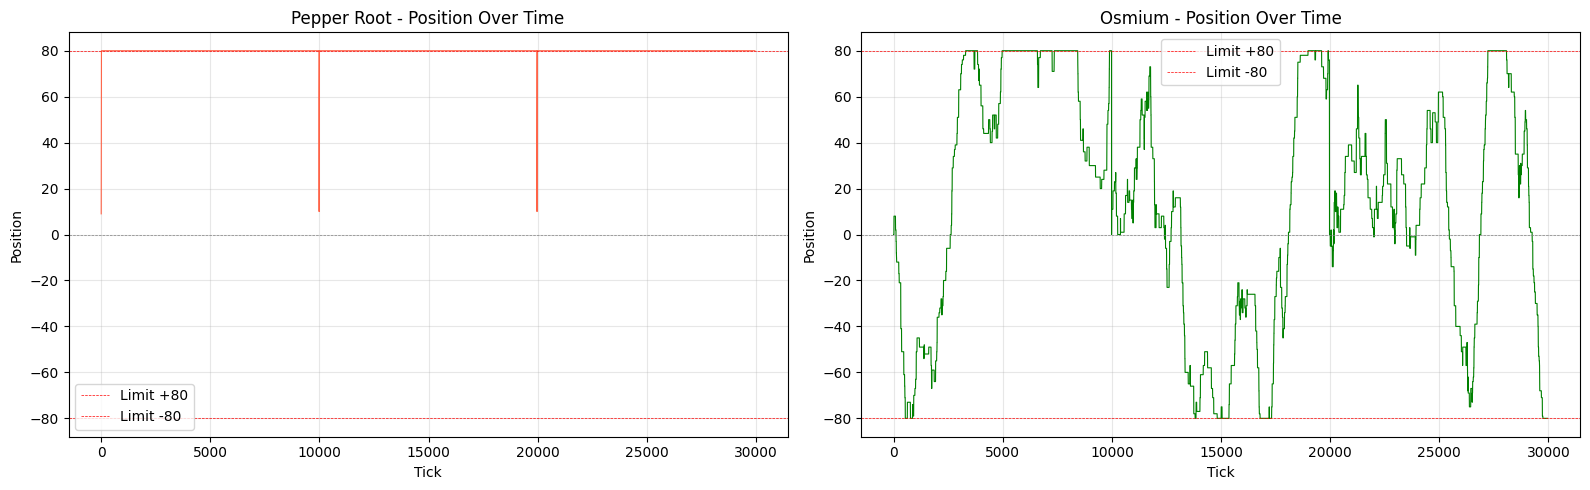

In [50]:
# ── Plot PnL over time per product ──
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, product, color, title in [
    (axes[0], "INTARIAN_PEPPER_ROOT", "tomato", "Pepper Root - PnL Over Time"),
    (axes[1], "ASH_COATED_OSMIUM", "green", "Osmium - PnL Over Time"),
]:
    prod = results_df[results_df["product"] == product].copy()
    if len(prod) > 0:
        prod["tick"] = range(len(prod))
        ax.plot(prod["tick"], prod["pnl"], linewidth=0.8, color=color)
        ax.set_title(title)
        ax.set_xlabel("Tick")
        ax.set_ylabel("PnL")
        ax.axhline(y=0, color="gray", linestyle="--", linewidth=0.5)
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ── Plot positions over time ──
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, product, color, title in [
    (axes[0], "INTARIAN_PEPPER_ROOT", "tomato", "Pepper Root - Position Over Time"),
    (axes[1], "ASH_COATED_OSMIUM", "green", "Osmium - Position Over Time"),
]:
    prod = results_df[results_df["product"] == product].copy()
    if len(prod) > 0:
        prod["tick"] = range(len(prod))
        ax.plot(prod["tick"], prod["position"], linewidth=0.8, color=color)
        ax.set_title(title)
        ax.set_xlabel("Tick")
        ax.set_ylabel("Position")
        ax.axhline(y=80, color="red", linestyle="--", linewidth=0.5, label="Limit +80")
        ax.axhline(y=-80, color="red", linestyle="--", linewidth=0.5, label="Limit -80")
        ax.axhline(y=0, color="gray", linestyle="--", linewidth=0.5)
        ax.legend()
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Submission logs visualiser (`submission_1`)

Loads Prosperity submission artefacts: **`*.json`** (round, status, profit, `activitiesLog`, `graphLog`, `positions`) and optional **`*.log`** (same plus `tradeHistory`, per-tick `logs`). Semicolon-separated CSV is parsed with pandas and plotted below.

In [51]:
from pathlib import Path
from io import StringIO
import json
from IPython.display import display

SUBMISSION_DIR = Path("logs2")

def load_submission_bundle(sub_dir: Path):
    """Merge JSON result + optional .log (adds tradeHistory, submissionId)."""
    json_files = sorted(sub_dir.glob("*.json"))
    log_files = sorted(sub_dir.glob("*.log"))
    if not json_files and not log_files:
        raise FileNotFoundError(f"No *.json or *.log in {sub_dir.resolve()}")

    meta = {}
    if json_files:
        with open(json_files[0], encoding="utf-8") as f:
            meta.update(json.load(f))
    if log_files:
        with open(log_files[0], encoding="utf-8") as f:
            log_obj = json.load(f)
        meta.setdefault("submissionId", log_obj.get("submissionId"))
        if "activitiesLog" not in meta and "activitiesLog" in log_obj:
            meta["activitiesLog"] = log_obj["activitiesLog"]
        if "tradeHistory" in log_obj:
            meta["tradeHistory"] = log_obj["tradeHistory"]

    activities = pd.read_csv(StringIO(meta["activitiesLog"]), sep=";")
    for c in activities.columns:
        if c not in ("day", "timestamp", "product"):
            activities[c] = pd.to_numeric(activities[c], errors="coerce")

    graph_df = None
    gl = meta.get("graphLog")
    if gl:
        graph_df = pd.read_csv(StringIO(gl), sep=";")
        graph_df.columns = [c.strip() for c in graph_df.columns]
        for c in graph_df.columns:
            graph_df[c] = pd.to_numeric(graph_df[c], errors="coerce")

    trades = meta.get("tradeHistory")
    trades_df = pd.DataFrame(trades) if trades else None

    return meta, activities, graph_df, trades_df

meta, sub_act, sub_graph, sub_trades = load_submission_bundle(SUBMISSION_DIR)

print("Files in", SUBMISSION_DIR.resolve())
for p in sorted(SUBMISSION_DIR.iterdir()):
    print(" ", p.name)

print("\n--- Result summary ---")
for k in ("round", "status", "profit"):
    if k in meta:
        print(f"  {k}: {meta[k]}")

if meta.get("positions"):
    display(pd.DataFrame(meta["positions"]))
if meta.get("submissionId"):
    print("submissionId:", meta["submissionId"])

print("\nactivities rows:", len(sub_act), "| columns:", list(sub_act.columns))
if sub_graph is not None:
    print("graphLog rows:", len(sub_graph))
if sub_trades is not None:
    print("tradeHistory rows:", len(sub_trades))

Files in /Users/devansharora/Desktop/Trading_System/IMC_Prosperity/Round_1/ROUND1/logs2
  169826.json
  169826.log
  169826.py

--- Result summary ---
  round: 1
  status: FINISHED
  profit: 8511.59375


,symbol,quantity
0,ASH_COATED_OSMIUM,5
1,INTARIAN_PEPPER_ROOT,80
2,XIRECS,-1009494


submissionId: 374c554f-0226-4ac3-b790-663db028678b

activities rows: 2000 | columns: ['day', 'timestamp', 'product', 'bid_price_1', 'bid_volume_1', 'bid_price_2', 'bid_volume_2', 'bid_price_3', 'bid_volume_3', 'ask_price_1', 'ask_volume_1', 'ask_price_2', 'ask_volume_2', 'ask_price_3', 'ask_volume_3', 'mid_price', 'profit_and_loss']
graphLog rows: 500
tradeHistory rows: 124


In [56]:
print(sub_act)

      day  timestamp               product  bid_price_1  bid_volume_1  \
0       0          0     ASH_COATED_OSMIUM       9992.0          23.0   
1       0          0  INTARIAN_PEPPER_ROOT      11991.0          20.0   
2       0        100  INTARIAN_PEPPER_ROOT      11994.0          12.0   
3       0        100     ASH_COATED_OSMIUM       9995.0          15.0   
4       0        200  INTARIAN_PEPPER_ROOT      11991.0          21.0   
...   ...        ...                   ...          ...           ...   
1995    0      99700  INTARIAN_PEPPER_ROOT      12090.0          23.0   
1996    0      99800     ASH_COATED_OSMIUM       9995.0          13.0   
1997    0      99800  INTARIAN_PEPPER_ROOT      12093.0          10.0   
1998    0      99900  INTARIAN_PEPPER_ROOT      12093.0          12.0   
1999    0      99900     ASH_COATED_OSMIUM       9995.0          10.0   

      bid_price_2  bid_volume_2  bid_price_3  bid_volume_3  ask_price_1  \
0             NaN           NaN          NaN    

In [73]:
print(os['ask_price_1'].iloc[0])

12006.0


In [80]:
shifted_df = os['bid_price_1'] - os['bid_price_1'].shift(1)
shifted_df[shifted_df>5]

123     10.0
189     13.0
287      9.0
635     13.0
652     13.0
979      7.0
1285     9.0
1468    13.0
1486     9.0
1547    12.0
1822    10.0
1875    10.0
Name: bid_price_1, dtype: float64

12070.0
12054.0


<Axes: >

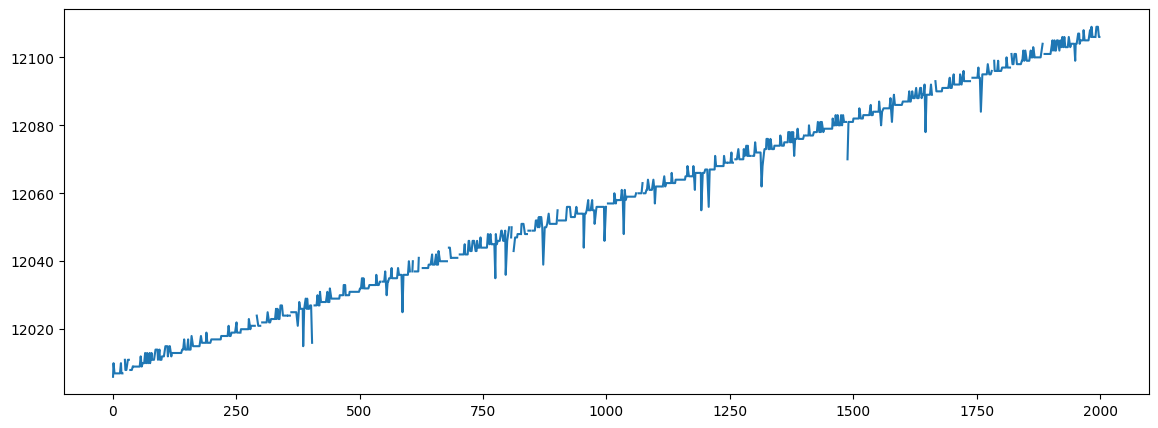

In [93]:
os = sub_act[sub_act['product']=='INTARIAN_PEPPER_ROOT']
os['ask_price_1'].plot()
#os['bid_price_1'].plot()

In [94]:
os['ask_price_1'].iloc[-1] - os['ask_price_1'].iloc[0]

np.float64(100.0)

In [97]:
print(os['ask_price_1'].iloc[0])
print(os['ask_price_1'].iloc[-1])

print(os['bid_price_1'].iloc[0])
print(os['bid_price_1'].iloc[-1])

12006.0
12106.0
11991.0
12093.0


<Axes: >

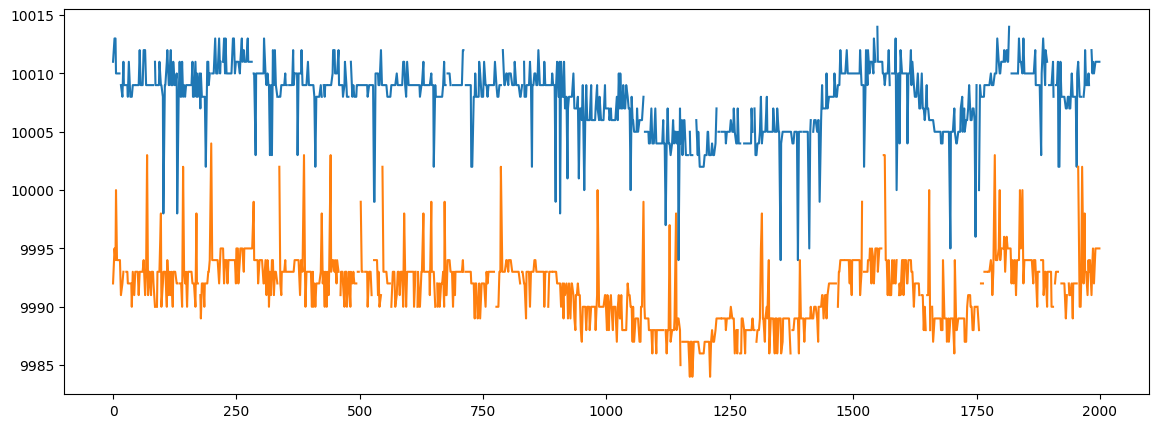

In [88]:
os = sub_act[sub_act['product']=='ASH_COATED_OSMIUM']
os['ask_price_1'].plot()
os['bid_price_1'].plot()

In [84]:
val = os['ask_price_1'].iloc[0] - os['bid_price_1'].iloc[0]
print(val)

15.0


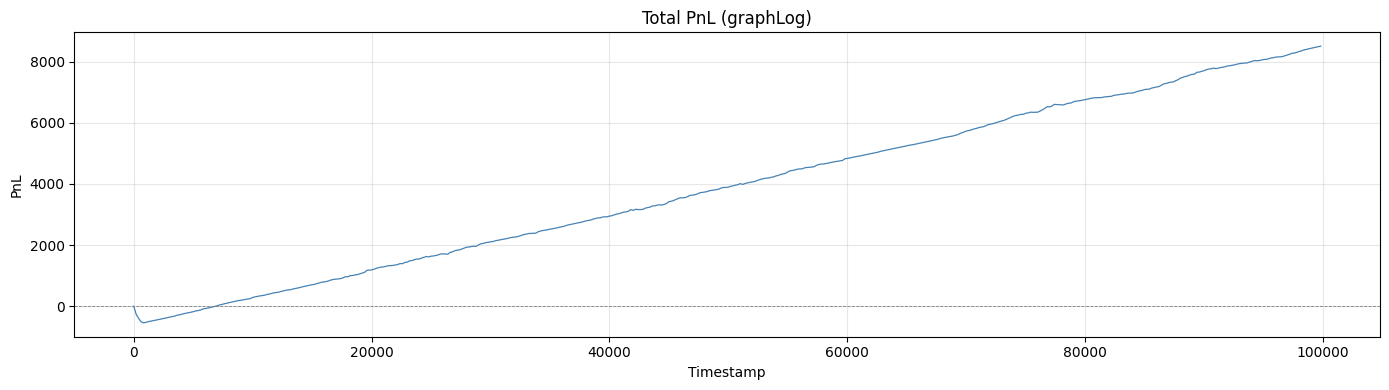

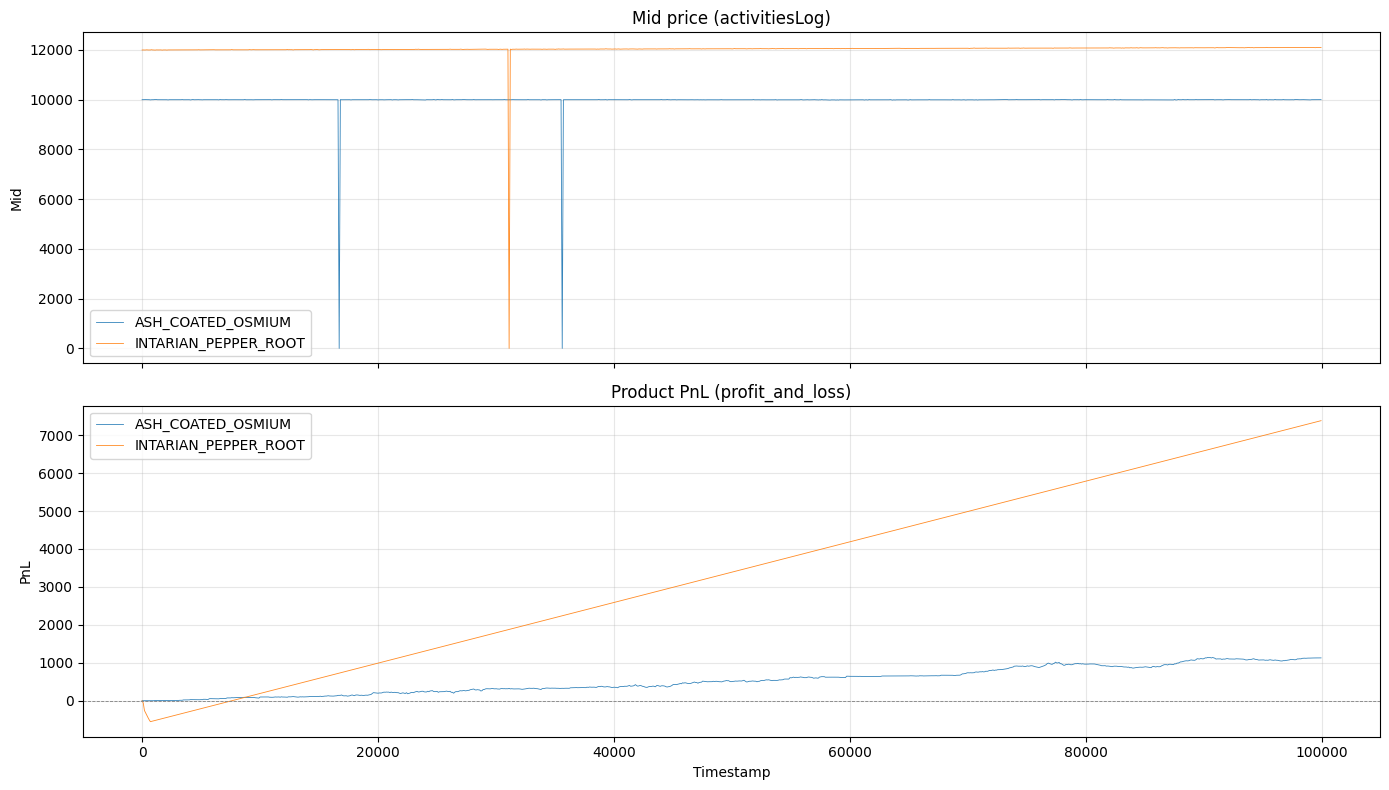

In [52]:
# ── Graph log: total PnL vs time (from submission JSON) ──
if sub_graph is not None and len(sub_graph) > 0:
    fig, ax = plt.subplots(figsize=(14, 4))
    cols = list(sub_graph.columns)
    tx, vx = cols[0], cols[1] if len(cols) > 1 else cols[0]
    ax.plot(sub_graph[tx], sub_graph[vx], linewidth=0.9, color="steelblue")
    ax.set_title("Total PnL (graphLog)")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("PnL")
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.6)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No graphLog in JSON — skip graph plot.")

# ── Per-product mid price & mark-to-market PnL from activitiesLog ──
products = [p for p in sub_act["product"].dropna().unique() if p in (
    "INTARIAN_PEPPER_ROOT", "ASH_COATED_OSMIUM"
)]
if not products:
    products = list(sub_act["product"].dropna().unique())

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for prod in products:
    d = sub_act[sub_act["product"] == prod].sort_values(["day", "timestamp"])
    axes[0].plot(d["timestamp"], d["mid_price"], linewidth=0.6, label=prod, alpha=0.9)
    if "profit_and_loss" in d.columns:
        axes[1].plot(d["timestamp"], d["profit_and_loss"], linewidth=0.6, label=prod, alpha=0.9)

axes[0].set_title("Mid price (activitiesLog)")
axes[0].set_ylabel("Mid")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Product PnL (profit_and_loss)")
axes[1].set_xlabel("Timestamp")
axes[1].set_ylabel("PnL")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.6)
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

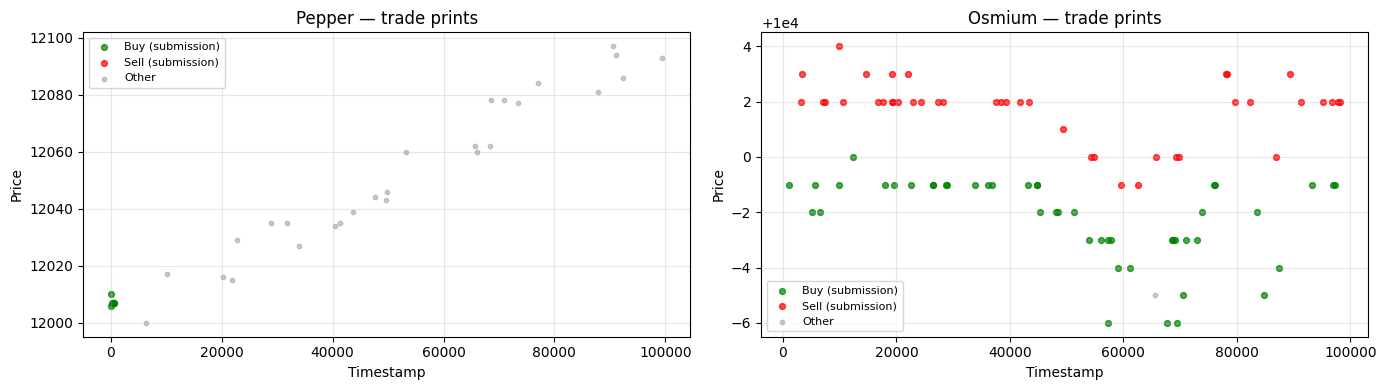

Trades by symbol:
 symbol
ASH_COATED_OSMIUM       90
INTARIAN_PEPPER_ROOT    34

Trades by side:
 side
?       28
BUY     54
SELL    42


In [53]:
# ── Trade history from *.log (fills involving SUBMISSION) ──
if sub_trades is not None and len(sub_trades) > 0:
    t = sub_trades.copy()
    t["side"] = "?"
    t.loc[t["buyer"].fillna("") == "SUBMISSION", "side"] = "BUY"
    t.loc[t["seller"].fillna("") == "SUBMISSION", "side"] = "SELL"
    both = (t["buyer"].fillna("") == "SUBMISSION") & (t["seller"].fillna("") == "SUBMISSION")
    t.loc[both, "side"] = "BOTH"

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for ax, sym, title in [
        (axes[0], "INTARIAN_PEPPER_ROOT", "Pepper — trade prints"),
        (axes[1], "ASH_COATED_OSMIUM", "Osmium — trade prints"),
    ]:
        ts = t[t["symbol"] == sym]
        buys = ts[ts["side"] == "BUY"]
        sells = ts[ts["side"] == "SELL"]
        ax.scatter(buys["timestamp"], buys["price"], s=18, alpha=0.7, label="Buy (submission)", color="green")
        ax.scatter(sells["timestamp"], sells["price"], s=18, alpha=0.7, label="Sell (submission)", color="red")
        oth = ts[~ts["side"].isin(["BUY", "SELL"])]
        if len(oth):
            ax.scatter(oth["timestamp"], oth["price"], s=10, alpha=0.4, label="Other", color="gray")
        ax.set_title(title)
        ax.set_xlabel("Timestamp")
        ax.set_ylabel("Price")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("Trades by symbol:\n", t.groupby("symbol").size().to_string())
    print("\nTrades by side:\n", t.groupby("side").size().to_string())
else:
    print("No tradeHistory in log — re-run after exporting a .log next to .json.")